# DL Part: CNN for Facial Emotion Recognition
Member: Kainat Ashraf

Steps: 1) download data, 2) explore, 3) preprocess + split, 4) build CNN, 5) train, 6) evaluate, 7) save the model for the app.

**Use a GPU:** Runtime > Change runtime type > T4 GPU. Then run the cells from top to bottom.

## 1. Install and load the dataset

In [1]:
!pip install -q kagglehub

In [2]:
import os, cv2, numpy as np, matplotlib.pyplot as plt
import kagglehub

# Downloads FER-2013 (train/test folders, one sub-folder per emotion)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

root = None
for dirpath, dirnames, _ in os.walk(path):
    if "train" in dirnames and "test" in dirnames:
        root = dirpath
        break
train_dir, test_dir = os.path.join(root, "train"), os.path.join(root, "test")
classes = sorted(os.listdir(train_dir))
print("Classes:", classes)

def load_split(folder):
    X, y = [], []
    for idx, cls in enumerate(classes):
        cls_dir = os.path.join(folder, cls)
        for name in os.listdir(cls_dir):
            img = cv2.imread(os.path.join(cls_dir, name), 0)       # grayscale
            if img is None:
                continue
            if img.shape != (48, 48):
                img = cv2.resize(img, (48, 48))
            X.append(img)
            y.append(idx)
    return np.array(X), np.array(y)

X_train_all, y_train_all = load_split(train_dir)
X_test, y_test = load_split(test_dir)
print("Train:", X_train_all.shape, " Test:", X_test.shape)

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train: (28709, 48, 48)  Test: (7178, 48, 48)


## 2. Explore the data
Note for the report: the Disgust class has far fewer images than the others (class imbalance).

angry       3995
disgust      436
fear        4097
happy       7215
neutral     4965
sad         4830
surprise    3171
Name: count, dtype: int64


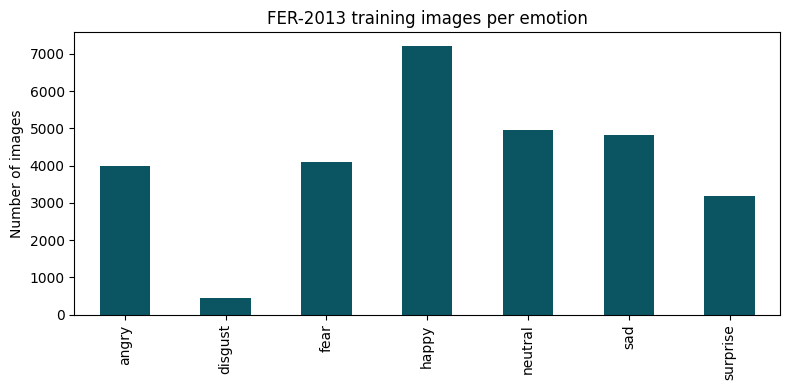

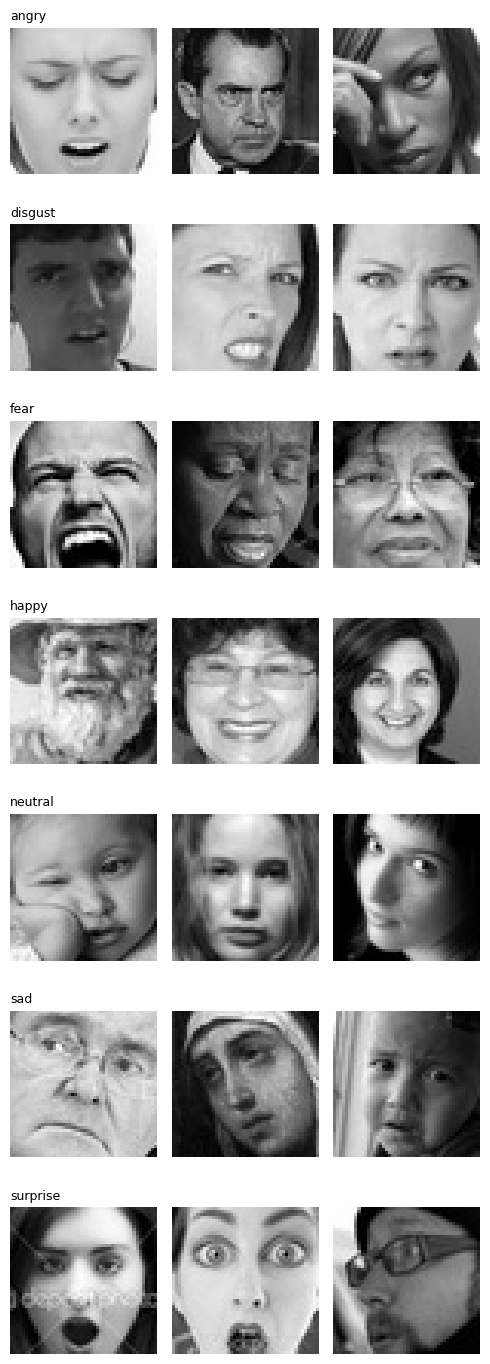

In [3]:
import pandas as pd

counts = pd.Series(y_train_all).map(lambda i: classes[i]).value_counts().reindex(classes)
print(counts)

plt.figure(figsize=(8, 4))
counts.plot(kind="bar", color="#0B5563")
plt.title("FER-2013 training images per emotion")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

# 3 sample images per emotion
fig, axes = plt.subplots(len(classes), 3, figsize=(5, 2 * len(classes)))
for r, cls_idx in enumerate(range(len(classes))):
    ids = np.where(y_train_all == cls_idx)[0][:3]
    for c, i in enumerate(ids):
        axes[r, c].imshow(X_train_all[i], cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(classes[cls_idx], fontsize=9, loc="left")
plt.tight_layout()
plt.show()

## 3. Preprocessing and train/validation/test split
Same split as the ML part (random_state=42, 15% validation), so the models can be compared fairly.

In [4]:
from sklearn.model_selection import train_test_split

# Same split for everyone in the group: random_state=42, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all, test_size=0.15, stratify=y_train_all, random_state=42
)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

# scale pixels to 0-1 and add a channel dimension: (N, 48, 48, 1)
X_train = (X_train.astype("float32") / 255.0)[..., None]
X_val   = (X_val.astype("float32") / 255.0)[..., None]
X_test_n = (X_test.astype("float32") / 255.0)[..., None]

Train: (24402, 48, 48) Validation: (4307, 48, 48) Test: (7178, 48, 48)


## 4. Build the CNN
Augmentation (flip, small rotation, zoom) is inside the model, so it only runs during training.

In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(0.25)(x)

inputs = keras.Input(shape=(48, 48, 1))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)
x = conv_block(x, 32)
x = conv_block(x, 64)
x = conv_block(x, 128)
x = layers.Flatten()(x)
x = layers.Dense(256)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(classes), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,470,951 (5.61 MB)

 Trainable params: 1,469,543 (5.61 MB)

 Non-trainable params: 1,408 (5.50 KB)

## 5. Train
Early stopping stops training when validation accuracy stops improving, and keeps the best weights.

In [6]:
from tensorflow import keras

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=callbacks,
)

Epoch 1/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.2699 - loss: 1.9354 - val_accuracy: 0.3116 - val_loss: 1.7450 - learning_rate: 0.0010
Epoch 2/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.3751 - loss: 1.6187 - val_accuracy: 0.4112 - val_loss: 1.4909 - learning_rate: 0.0010
Epoch 3/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.4431 - loss: 1.4497 - val_accuracy: 0.4952 - val_loss: 1.3182 - learning_rate: 0.0010
Epoch 4/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.4783 - loss: 1.3543 - val_accuracy: 0.5312 - val_loss: 1.2355 - learning_rate: 0.0010
Epoch 5/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.5015 - loss: 1.3073 - val_accuracy: 0.5159 - val_loss: 1.2583 - learning_rate: 0.0010
Epoch 6/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.5153 - loss: 1.2765 - val_accuracy: 0.4904 - val_loss: 1.3702 - learning_rate: 0.0010
Epoch 7/15
382/382 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.5244 - l

## 6. Training curves (for the report)

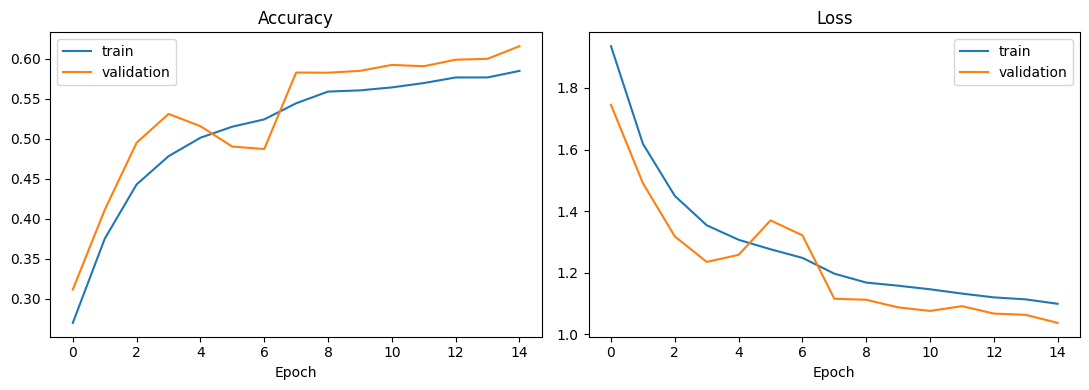

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Evaluate on the test set

              precision    recall  f1-score   support

       angry       0.50      0.55      0.52       958
     disgust       0.80      0.11      0.19       111
        fear       0.50      0.24      0.33      1024
       happy       0.78      0.88      0.82      1774
     neutral       0.55      0.58      0.56      1233
         sad       0.46      0.56      0.51      1247
    surprise       0.77      0.71      0.74       831

    accuracy                           0.61      7178
   macro avg       0.62      0.52      0.52      7178
weighted avg       0.61      0.61      0.59      7178



,Model,Test accuracy,Precision (macro),Recall (macro),F1 (macro)
0,CNN,0.6066,0.6218,0.5192,0.5248


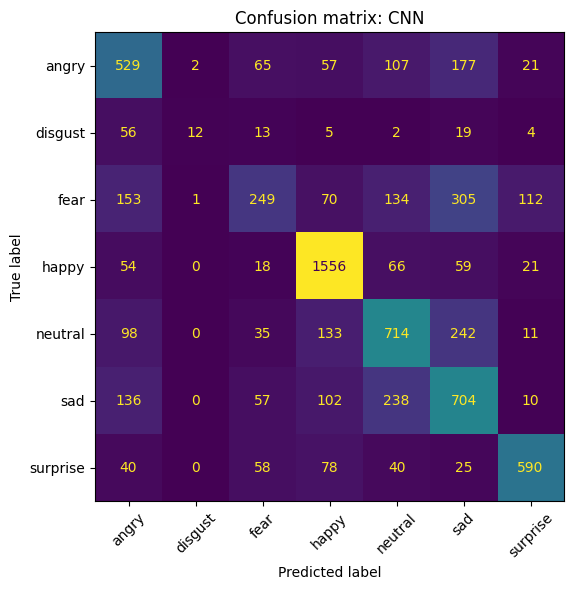

In [8]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
import pandas as pd

pred = model.predict(X_test_n, verbose=0).argmax(axis=1)

print(classification_report(y_test, pred, target_names=classes, zero_division=0))

row = {
    "Model": "CNN",
    "Test accuracy": round(accuracy_score(y_test, pred), 4),
    "Precision (macro)": round(precision_score(y_test, pred, average="macro", zero_division=0), 4),
    "Recall (macro)": round(recall_score(y_test, pred, average="macro", zero_division=0), 4),
    "F1 (macro)": round(f1_score(y_test, pred, average="macro", zero_division=0), 4),
}
display(pd.DataFrame([row]))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=classes, xticks_rotation=45, ax=ax, colorbar=False
)
ax.set_title("Confusion matrix: CNN")
plt.tight_layout()
plt.show()

## 8. Save the model for the app
Send **both downloaded files** to Wardah (CV part) so she can plug the model into the face detection pipeline.

In [9]:
import json
from google.colab import files

model.save("emotion_cnn.keras")
with open("classes.json", "w") as f:
    json.dump(classes, f)

files.download("emotion_cnn.keras")
files.download("classes.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Quick prediction test (this is how the model is used in the app)

In [10]:
def predict_emotion(face48):
    """face48: 48x48 grayscale image (uint8)"""
    x = face48.astype("float32") / 255.0
    x = x.reshape(1, 48, 48, 1)
    probs = model.predict(x, verbose=0)[0]
    return classes[int(probs.argmax())], probs

label, probs = predict_emotion(X_test[0])
print("Predicted:", label, "| Actual:", classes[y_test[0]])

Predicted: happy | Actual: angry
